Universidad Torcuato Di Tella

*Licenciatura en Tecnología Digital*

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**
# **Trabajo Práctico — Ejercicio N°5: Reconstrucción en condiciones ideales**

Antes de comenzar a resolver, importamos los módulos que utilizaremos en el desarrollo.

In [1]:
# Importamos los módulos
import numpy as np
import matplotlib.pyplot as plt

# Pandas es para armar la tabla
import pandas as pd

Además, corremos los bloques necesarios de ejercicios anteriores para poder realizar este ejercicio:

In [2]:
# Ejercicio 3

# Definimos `X_fantoma`
X_fantoma:np.ndarray = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

# Aplanamos la matriz `X_fantoma` para dar lugar a `x_fantoma`
x_fantoma = X_fantoma.reshape(-1)

In [3]:
# Ejercicio 3
def mascara_rayo(n:int, direccion:tuple[int,int], s:int):
    r'''
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direccion` -> dirección del rayo (fija una familia de rayos paralelos).
    - `s` -> distancia del rayo al origen (fija un rayo).

    Devuelve:
    - La matriz que representa la mascara del rayo sobre la imagen.
    '''
    res:np.ndarray = np.zeros(shape=(n,n), dtype=np.int8)
    for i in range(0,len(res)):
        for j in range(0,len(res)):
            if (direccion[0] * i) + (direccion[1] * j) == s:
                res[i][j] = 1
    return res

In [4]:
# Ejercicio 3
def matriz_proyeccion(n:int, direcciones:list[tuple[int, int]]):
    r'''
    
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direcciones` -> vector de direcciones a utilizar.

    Devuelve:
    - La matriz compuesta por las máscaras de todos los rayos correspondientes.
    - La lista de todos los rayos generados, con el ángulo y el s correspondiente.
    '''
    A:list[list[int]] = list()
    res:list[tuple[tuple[int,int], int]] = list()
    for dir in direcciones:
        rayos:set[int] = set()
        for i in range(n):
            for j in range(n):
                s = dir[0] * i + dir[1] * j
                rayos.add(s)
        rayos_lista:list[int] = list(rayos)
        rayos_lista.sort()
        rayos_array:np.ndarray = np.array(rayos_lista)

        for rayo in rayos_array:
            fila_A = mascara_rayo(n, dir, rayo)
            fila_A = fila_A.reshape(-1)
            A.append(fila_A) # type: ignore
            res.append((dir, rayo))

    return A, res

In [5]:
# Ejercicio 4

# Para definir dimensiones de la matriz (nxn)
n = 8

D2 = [(1,0),(0,1)]
D4 = [(1,0),(0,1),(1,1),(1,-1)]
D7 = [(1,0),(0,1),(1,1),(1,-1),(2,1),(1,2),(3,1)]

# Construímos A2, A4, A7
A2 = matriz_proyeccion(n, D2)[0]
A4 = matriz_proyeccion(n, D4)[0]
A7 = matriz_proyeccion(n, D7)[0]

Continuaremos utilizando el vector $x_{\text{fantoma}}$ del Ejercicio 1 y las matrices $A_2$, $A_4$ y $A_7$ construidas anteriormente. Trabajaremos con mediciones ideales, sin ruido, para observar cómo el rango de la matriz de proyección afecta la reconstrucción. En particular, $A_7$ tiene rango columna completo, mientras que
$A_2$ y $A_4$ no determinan una solución única

1. Para cada $k \in \{2,4,7\}$, generar las mediciones $b_k = A_k x_{\text{fantoma}}$ y resolver el sistema mediante `np.linalg.lstsq` para obtener una reconstrucción $\hat{x}_k$. En los casos sin solución única, esta función devolverá una solución de norma mínima.

In [6]:
# Generemos las mediciones
b2 = A2 @ x_fantoma
b4 = A4 @ x_fantoma
b7 = A7 @ x_fantoma

Graficamos las mediciones de forma separada.

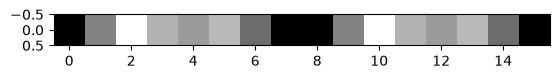

In [7]:
plt.imshow([b2], cmap='gray')

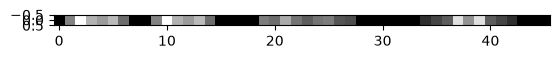

In [8]:
plt.imshow([b4], cmap='gray')

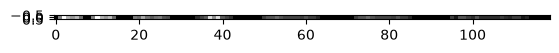

In [9]:
plt.imshow([b7], cmap='gray')

A continuación, resolvemos los sistemas de forma separada por mínimos cuadrados.

In [10]:
x_2_approx = np.linalg.lstsq(A2, b2)[0]
x_4_approx = np.linalg.lstsq(A4, b4)[0]
x_7_approx = np.linalg.lstsq(A7, b7)[0]

Convertimos los vectores $\hat{x}_k$ en matrices $\hat{X}_k$.

In [11]:
X_2_approx = x_2_approx.reshape(8,8)
X_4_approx = x_4_approx.reshape(8,8)
X_7_approx = x_7_approx.reshape(8,8)

A continuación, graficamos las imágenes obtenidas de la reconstrucción por mínimos cuadrados.

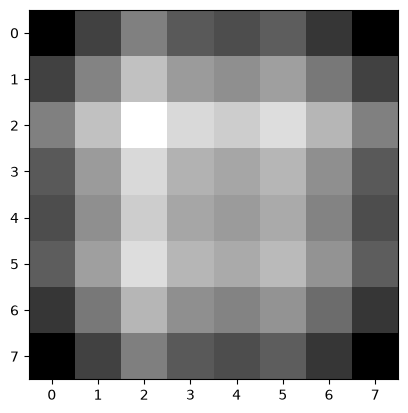

In [12]:
plt.imshow(X_2_approx, cmap="gray")

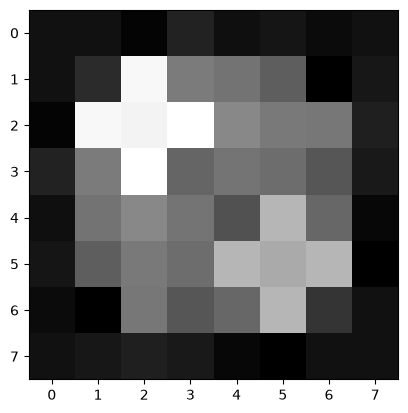

In [13]:
plt.imshow(X_4_approx, cmap="gray")

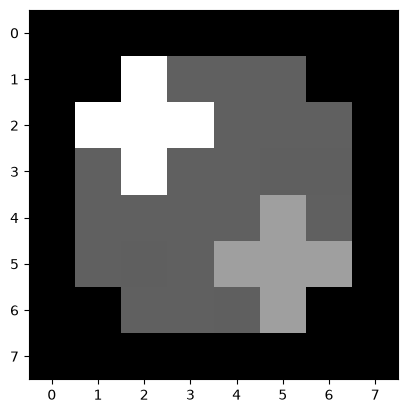

In [14]:
plt.imshow(X_7_approx, cmap="gray")

2. Para cada reconstrucción, calcular el residuo $r_k = b_k −A_k \hat{x}_k$ y su norma. Calcular también el error relativo dividiendo $||\hat{x}_k −x_{\text{fantoma}}||$ por $||x_\text{fantoma}||$. Resumir en una tabla el rango de $A_k$, la norma del residuo y el error relativo.


In [15]:
# Calculamos el residuo res_k para cada reconstrucción
res_2 = b2 - (A2 @ x_2_approx)
res_4 = b4 - (A4 @ x_4_approx)
res_7 = b7 - (A7 @ x_7_approx)

In [16]:
# Para cada reconstrucción calculamos el error relativo
err_rel_2 = np.linalg.norm(x_2_approx - x_fantoma)/np.linalg.norm(x_fantoma)
err_rel_4 = np.linalg.norm(x_4_approx - x_fantoma)/np.linalg.norm(x_fantoma)
err_rel_7 = np.linalg.norm(x_7_approx - x_fantoma)/np.linalg.norm(x_fantoma)

In [17]:
# Calculamos el rango para cada A_k
rank_A2 = np.linalg.matrix_rank(A2)
rank_A4 = np.linalg.matrix_rank(A4)
rank_A7 = np.linalg.matrix_rank(A7)

In [18]:
# Creamos una tabla con todos los datos solicitados
tabla = pd.DataFrame({
    "rango": [rank_A2, rank_A4, rank_A7],
    "norma del residuo": [np.linalg.norm(res_2), np.linalg.norm(res_4), np.linalg.norm(res_7)],
    "error relativo": [round(float(err_rel_2), 2), round(float(err_rel_4), 2) , err_rel_7]
})

tabla

,rango,norma del residuo,error relativo
0,15,4.988442e-15,4.700000e-01
1,39,1.288039e-14,1.400000e-01
2,64,1.485822e-14,2.137106e-15


Un residuo cercano a cero no hace más que sugerir un vector factible tal que al aplicarse $A_k$ se asimile lo más que pueda a las mediciones en $b_k$. Por ende, es una aproximación y no garantiza que la imagen haya sido reconstruida pues no hay modo que eso ocurra salvo que $A_k$ sea invertible, es decir, que $\text{Dim}(\text{null}(A_k)) = 0$ (por teorema de la matriz invertible). 